# Experiment 1: Long-Text Handling — Head + Tail vs. Chunk Averaging

### Motivation

Approximately 64% of our training and validation texts exceed XLM-RoBERTa's 512-token input limit.

Our reference encoder handles long documents using head + tail truncation, keeping the first 320 and last 190 content tokens.

Although this strategy preserves the beginning and conclusion of a text, it discards information from the middle.

This limitation may be particularly important for detecting `fusion` texts, where AI-generated passages may appear anywhere within an otherwise human-written document.

### Hypothesis

Processing several chunks from different parts of a document and aggregating their predictions may improve macro-F1 and `fusion` recall compared with head + tail truncation.

### Experimental Design

We compare two inference strategies using the **same fine-tuned XLM-RoBERTa checkpoint selected at epoch 4**:

1. **Reference:** Head + tail truncation (320 beginning + 190 ending tokens).
2. **Experiment:** Sliding-window chunking with probability averaging.

All model weights, validation examples, label mappings, and evaluation metrics remain fixed.

Only the text-processing strategy at inference time changes.

### Expected Outcome

Chunk averaging may improve classification of long documents by preserving more textual information. However, it could also reduce performance because the encoder was fine-tuned on head + tail inputs rather than individual sliding-window chunks.

The experiment will determine whether the additional document coverage improves classification in practice.

*(The exact share of texts over the limit is measured and printed in section 4; no model is trained in this notebook.)*

## 2. Hypothesis and reference results

| Model | Validation macro-F1 |
|---|---|
| TF-IDF + Logistic Regression (C=3) | 0.8644 |
| XLM-RoBERTa, head + tail, best epoch 4 (reference) | **0.9049** |

**What must be attached in Kaggle (Add Input):** the saved output of the completed encoder notebook, i.e. the folder `encoder_outputs/` containing `best_model/` (the epoch-4 checkpoint and tokenizer) and, ideally, `xlmr_probs.npz` and `run_config.json`. Save a version of the encoder notebook, then attach its output (or a Kaggle dataset made from it) to this notebook. The notebook finds it by searching `/kaggle/input/**/best_model/`.

**Restrictions respected:** no training or fine-tuning, no epoch-2 / epoch-6 weights, no pretrained-backbone substitute, no change of split or preprocessing, no TF-IDF, no extra features, no ensembling. The notebook fails with a clear error if the checkpoint is missing.

## 3. Imports and configuration

In [1]:
import os, gc, glob, json, time, random, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, transformers
from scipy.stats import binomtest
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModelForSequenceClassification
transformers.logging.set_verbosity_warning()

# ---------------- configuration ----------------
SEED, N_SUB, VAL_FRAC = 42, 40_000, 0.2
EXPECTED_FINGERPRINT = "97fed7e0aa8163e74359d495ffc4a025"       # md5 of the comma-joined validation ids, in order
MAX_LEN, HEAD_TOKENS, TAIL_TOKENS = 512, 320, 190               # reference preprocessing (must equal the encoder notebook)
WINDOW, STRIDE, MAX_CHUNKS = 510, 384, 6                        # chunking parameters (content tokens; 2 special tokens are added on top)
INFER_BS = 16                                                   # inference batch size (halved automatically on CUDA out-of-memory)
DOC_BATCH = 512                                                 # documents processed at a time (limits RAM)
MIN_GROUP_N = 100                                               # smallest group for which macro-F1 is reported
EXPECTED_BEST_EPOCH, REF_F1, BASELINE_F1, REF_TOL = 4, 0.9049, 0.8644, 0.003
MODEL_DIR_OVERRIDE = None                                       # set to a folder path to bypass the automatic search
ALLOW_CPU = False
LABELS = ["human", "ai", "fusion"]; label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}
OUT_DIR = "/kaggle/working/experiment_1_outputs" if os.path.isdir("/kaggle/working") else "./experiment_1_outputs"; os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEV = "cuda" if torch.cuda.is_available() else "cpu"; USE_FP16 = DEV == "cuda"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device:", DEV, torch.cuda.get_device_name(0) if USE_FP16 else "")
if DEV == "cpu" and not ALLOW_CPU: raise RuntimeError("No GPU found. Kaggle: Settings -> Accelerator -> GPU (one GPU is enough; this notebook uses a single device).")

torch 2.11.0+cu130 | transformers 5.20.2 | device: cuda Tesla T4


## 4. Dataset and reproducible validation split
The split code is the one used by the baseline and by the encoder notebook. The md5 fingerprint of the validation ids must match the value recorded for the completed encoder run.

In [2]:
_hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
assert _hits, "train.csv not found: add the competition via 'Add Input'"
DATA_DIR = os.path.dirname(_hits[0])
train = pd.read_csv(f"{DATA_DIR}/train.csv"); test = pd.read_csv(f"{DATA_DIR}/test.csv"); sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
for d in (train, test): d["text"] = d["text"].fillna("").astype(str)
assert train.id.is_unique and test.id.is_unique and len(test) == len(sub_tmpl) == 25000 and set(sub_tmpl.label.unique()) <= set(LABELS)

sub = train.sample(N_SUB, random_state=SEED).reset_index(drop=True)
tr_df, va_df = train_test_split(sub, test_size=VAL_FRAC, random_state=SEED, stratify=sub.label + "_" + sub.lang)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)       # (the training part is not used here)
yva = va_df.label.map(label2id).values
FINGERPRINT = hashlib.md5(",".join(va_df.id).encode()).hexdigest()
assert len(va_df) == 8000 and va_df.id.is_unique
assert FINGERPRINT == EXPECTED_FINGERPRINT, f"validation split differs from the encoder run: {FINGERPRINT} != {EXPECTED_FINGERPRINT}. Check the data version and the split code; do not compare predictions across different splits."
print("validation fingerprint OK:", FINGERPRINT, "| validation shares:", va_df.label.value_counts(normalize=True).round(3).to_dict())

validation fingerprint OK: 97fed7e0aa8163e74359d495ffc4a025 | validation shares: {'ai': 0.449, 'fusion': 0.307, 'human': 0.244}


## 5. Load the best epoch-4 encoder checkpoint
The fine-tuned `best_model/` directory saved by the encoder notebook (weights of the epoch selected by validation macro-F1). If it cannot be found the notebook stops; it never falls back to the pretrained backbone.

In [3]:
if MODEL_DIR_OVERRIDE: MODEL_DIR = MODEL_DIR_OVERRIDE
else:
    found = sorted(glob.glob("/kaggle/input/**/best_model/config.json", recursive=True))
    if not found: raise FileNotFoundError("Fine-tuned checkpoint not found. Save a version of the encoder notebook, then attach its output (the folder 'encoder_outputs/' with 'best_model/') via 'Add Input' -> your notebook output / dataset. The original 'FacebookAI/xlm-roberta-base' is NOT a valid substitute and is deliberately not used.")
    if len(found) > 1:
        raise RuntimeError("Multiple best_model checkpoints found: " + str([os.path.dirname(f) for f in found]) + ". Set MODEL_DIR_OVERRIDE explicitly to the epoch-4 encoder checkpoint.")
    MODEL_DIR = os.path.dirname(found[0]); print("checkpoint candidate:", MODEL_DIR)
print("checkpoint:", MODEL_DIR, "|", sorted(os.listdir(MODEL_DIR)))
assert any(f.endswith((".safetensors", ".bin")) for f in os.listdir(MODEL_DIR)), "no weight file in the checkpoint folder"

# run_config.json (written by the encoder notebook next to best_model/) lets us verify epoch and preprocessing
rc_path = os.path.join(os.path.dirname(MODEL_DIR), "run_config.json"); RUN_CONFIG = None
if os.path.exists(rc_path):
    RUN_CONFIG = json.load(open(rc_path))
    assert RUN_CONFIG["best_epoch"] == EXPECTED_BEST_EPOCH, f"checkpoint comes from best epoch {RUN_CONFIG['best_epoch']}, expected {EXPECTED_BEST_EPOCH}"
    assert (RUN_CONFIG["max_len"], RUN_CONFIG["head_tokens"], RUN_CONFIG["tail_tokens"]) == (MAX_LEN, HEAD_TOKENS, TAIL_TOKENS), "preprocessing differs from the encoder run"
    assert RUN_CONFIG.get("val_id_fingerprint", FINGERPRINT) == FINGERPRINT, "encoder run used a different validation split"
    print(f"run_config.json verified: best epoch {RUN_CONFIG['best_epoch']}, best val macro-F1 {RUN_CONFIG['best_val_macro_f1']:.4f}")
else: print("WARNING: run_config.json not found next to best_model/ -> the epoch cannot be verified from metadata; it is verified through the reference predictions below instead.")

tok = AutoTokenizer.from_pretrained(MODEL_DIR); model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)
assert model.config.num_labels == 3 and model.config.label2id == label2id and model.config.id2label == id2label, (model.config.label2id, "label mapping differs from human=0, ai=1, fusion=2")
assert tok.num_special_tokens_to_add(pair=False) == 2 and WINDOW == MAX_LEN - 2 and HEAD_TOKENS + TAIL_TOKENS == WINDOW
model.to(DEV).eval(); PAD = tok.pad_token_id
for p in model.parameters(): p.requires_grad_(False)                                  # inference only: no gradient updates anywhere in this notebook
print("model loaded:", sum(p.numel() for p in model.parameters()) / 1e6, "M parameters | labels:", model.config.id2label)

checkpoint candidate: /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/best_model
checkpoint: /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/best_model | ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
run_config.json verified: best epoch 4, best val macro-F1 0.9049


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model loaded: 278.045955 M parameters | labels: {0: 'human', 1: 'ai', 2: 'fusion'}


## 6. Reproduce head + tail predictions
Preprocessing is identical to the encoder notebook: tokenize without special tokens and without truncation; a text with more than 510 tokens keeps its first 320 and last 190 tokens; `<s>` and `</s>` are added afterwards; batches are padded dynamically. The same inference engine (batched, fp16, out-of-memory safe) is used for both strategies, so any difference comes only from the text-processing strategy.

In [4]:
def tokenize_raw(texts, bs=512):
    out = []
    for i in range(0, len(texts), bs): out += [np.asarray(x, dtype=np.int32) for x in tok(list(texts[i:i+bs]), add_special_tokens=False, truncation=False)["input_ids"]]
    return out
t0 = time.time(); va_raw = tokenize_raw(va_df.text.tolist()); te_raw = tokenize_raw(test.text.tolist()); print(f"tokenised in {time.time()-t0:.0f}s")
va_len, te_len = np.array([len(x) for x in va_raw]), np.array([len(x) for x in te_raw])
print(f"raw token length: validation median {int(np.median(va_len))}, max {va_len.max()} | share over {WINDOW} tokens: validation {(va_len > WINDOW).mean():.3f}, test {(te_len > WINDOW).mean():.3f}")

def add_special(ids):
    # Transformers 5.x XLMRobertaTokenizer does not expose build_inputs_with_special_tokens.
    return np.asarray([tok.cls_token_id] + [int(x) for x in ids] + [tok.sep_token_id], dtype=np.int64)
def view_headtail(ids):
    if len(ids) > WINDOW: ids = np.concatenate([ids[:HEAD_TOKENS], ids[-TAIL_TOKENS:]])
    return [add_special(ids)]

@torch.no_grad()
def forward_probs(seqs):
    # class probabilities of a list of token-id arrays; batches are sorted by length (little padding), padded dynamically, fp16 autocast,
    # and the batch size is halved automatically on CUDA out-of-memory. Results are returned in the original order.
    global INFER_BS
    n = len(seqs); out = np.zeros((n, 3), np.float32); order = np.argsort([len(s) for s in seqs]); i = 0
    while i < n:
        idx = order[i:i + INFER_BS]
        try:
            L = (max(len(seqs[j]) for j in idx) + 7) // 8 * 8
            ids = torch.full((len(idx), L), PAD, dtype=torch.long); att = torch.zeros_like(ids)
            for r, j in enumerate(idx): s = seqs[j]; ids[r, :len(s)] = torch.from_numpy(s.astype(np.int64)); att[r, :len(s)] = 1
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
                logits = model(input_ids=ids.to(DEV), attention_mask=att.to(DEV)).logits.float()
            out[idx] = torch.softmax(logits, dim=-1).cpu().numpy(); i += len(idx)
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and INFER_BS > 1: torch.cuda.empty_cache(); INFER_BS = max(1, INFER_BS // 2); print("CUDA OOM -> inference batch size", INFER_BS)
            else: raise
    return out

def predict_docs(raw, view_fn, name=""):
    # view_fn(ids) -> list of input sequences of ONE document; the class probabilities of its sequences are averaged.
    N = len(raw); P = np.zeros((N, 3), np.float32); n_seq = np.zeros(N, dtype=int); t0 = time.time()
    for s in range(0, N, DOC_BATCH):
        seqs, owner = [], []
        for k in range(s, min(s + DOC_BATCH, N)): v = view_fn(raw[k]); seqs += v; owner += [k - s] * len(v); n_seq[k] = len(v)
        pr = forward_probs(seqs); owner = np.array(owner)                              # owner is non-decreasing: chunks of a document are contiguous
        first = np.flatnonzero(np.r_[True, owner[1:] != owner[:-1]]); cnt = np.diff(np.r_[first, len(owner)])
        P[s:s + len(first)] = np.add.reduceat(pr, first, axis=0) / cnt[:, None]
        if (s // DOC_BATCH) % 4 == 0: print(f"  {name}: {min(s + DOC_BATCH, N)}/{N} docs ({time.time()-t0:.0f}s)")
    return P, n_seq, time.time() - t0

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1183 > 512). Running this sequence through the model will result in indexing errors


tokenised in 34s
raw token length: validation median 669, max 6080 | share over 510 tokens: validation 0.641, test 0.615


In [5]:
def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    d = {"macro_f1": f1_score(y, pred, average="macro"), "accuracy": accuracy_score(y, pred)}
    for i, l in enumerate(LABELS): d[f"precision_{l}"], d[f"recall_{l}"], d[f"f1_{l}"] = float(p[i]), float(r[i]), float(f[i])
    return d

# (a) recompute head + tail with the loaded checkpoint (also gives its inference time)
P_ht_re, _, T_HT_VAL = predict_docs(va_raw, view_headtail, "head+tail val"); m_re = metrics(yva, P_ht_re.argmax(1))
print(f"recomputed head+tail: macro-F1 {m_re['macro_f1']:.4f} ({T_HT_VAL:.0f}s)")

# (b) saved reference probabilities from the encoder run, if attached
ref_files = sorted(glob.glob("/kaggle/input/**/xlmr_probs.npz", recursive=True)); P_ht_saved = None
if ref_files:
    z = np.load(ref_files[0], allow_pickle=True)
    assert list(z["va_ids"]) == va_df.id.tolist(), "saved validation ids differ from our validation ids/order"
    assert np.array_equal(z["yva"], yva) and list(z["classes"]) == LABELS, "saved labels / class order differ"
    P_ht_saved = z["P_va"].astype(np.float32); m_saved = metrics(yva, P_ht_saved.argmax(1)); REF_SOURCE = f"saved encoder predictions ({ref_files[0]})"
    print(f"saved reference: macro-F1 {m_saved['macro_f1']:.4f} | agreement of recomputed vs saved predictions: {(P_ht_re.argmax(1) == P_ht_saved.argmax(1)).mean():.4f} | max |dP| {np.abs(P_ht_re - P_ht_saved).max():.4f}")
    assert abs(m_re["macro_f1"] - m_saved["macro_f1"]) < REF_TOL, "recomputed head+tail disagrees with the saved predictions: check checkpoint, label mapping, ids and preprocessing"
    P_ht = P_ht_saved
else:
    print("xlmr_probs.npz not found -> the recomputed head+tail predictions are the reference"); P_ht = P_ht_re; REF_SOURCE = "recomputed from the loaded best_model checkpoint"
REF = metrics(yva, P_ht.argmax(1)); pred_ht = P_ht.argmax(1)
print(f"REFERENCE head+tail macro-F1 = {REF['macro_f1']:.4f} (expected about {REF_F1}) | source: {REF_SOURCE}")
assert abs(REF["macro_f1"] - REF_F1) < REF_TOL, f"reference macro-F1 {REF['macro_f1']:.4f} is not ~{REF_F1}: investigate checkpoint, label mapping, validation ids and preprocessing before comparing methods"

  head+tail val: 512/8000 docs (6s)
  head+tail val: 2560/8000 docs (17s)
  head+tail val: 4608/8000 docs (28s)
  head+tail val: 6656/8000 docs (39s)
recomputed head+tail: macro-F1 0.9049 (47s)
saved reference: macro-F1 0.9049 | agreement of recomputed vs saved predictions: 1.0000 | max |dP| 0.0245
REFERENCE head+tail macro-F1 = 0.9049 (expected about 0.9049) | source: saved encoder predictions (/kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/xlmr_probs.npz)


## 7. Implement sliding-window chunk averaging
For each document (tokens without special tokens, no initial truncation):
1. windows of up to **510 content tokens** start every **384 tokens** (overlap 126), plus one last window that ends exactly at the final token, so the ending is always included;
2. if there are more than **6** windows, 6 are kept at evenly spaced positions in the list (first and last always kept, the rest cover the middle);
3. `<s>`/`</s>` are added to every chunk, each chunk is classified, the softmax probabilities of the chunks of one document are **averaged**, and the argmax is the prediction.

A text of at most 510 tokens gives exactly one chunk, which is identical to its head + tail input; this is checked below. (For texts just above 510 tokens the first and the last window overlap almost completely; this redundancy is harmless.) The earlier Section 5a implementation took the first windows only (the tail was added in a later version); here coverage of the middle and the end is explicit.

In [6]:
def window_starts(n):
    if n <= WINDOW: return [0]
    return sorted(set(list(range(0, n - WINDOW, STRIDE)) + [n - WINDOW]))          # regular windows + the window that ends at the last token
def select_starts(starts):
    if len(starts) <= MAX_CHUNKS: return starts
    keep = np.unique(np.linspace(0, len(starts) - 1, MAX_CHUNKS).round().astype(int)); return [starts[i] for i in keep]
def view_chunks(ids): return [add_special(ids[s:s + WINDOW]) for s in select_starts(window_starts(len(ids)))]
def covered_fraction(n, starts):
    ivs = sorted((s, min(s + WINDOW, n)) for s in starts); cov, end = 0, 0
    for a, b in ivs: cov += max(0, b - max(a, end)); end = max(end, b)
    return cov / max(n, 1)

# structure checks on synthetic lengths
for n in [20, 510, 511, 900, 2430, 2431, 3000, 5000]:
    st_ = select_starts(window_starts(n)); assert len(st_) <= MAX_CHUNKS and st_[0] == 0 and st_[-1] == max(n - WINDOW, 0) and all(0 <= s <= max(n - WINDOW, 0) for s in st_)
    assert all(len(c) <= MAX_LEN for c in [np.arange(min(WINDOW, n - s)) for s in st_]), n

cand_n = np.array([len(window_starts(n)) for n in va_len]); n_used = np.minimum(cand_n, MAX_CHUNKS)
cov_ct = np.array([covered_fraction(n, select_starts(window_starts(n))) for n in va_len]); cov_ht = np.minimum(WINDOW, va_len) / va_len
print("chunks per validation document (used):", pd.Series(n_used).value_counts().sort_index().to_dict(), f"| mean {n_used.mean():.2f}, median {np.median(n_used):.0f}")
print(f"documents with more than {MAX_CHUNKS} candidate windows (chunks selected evenly): {(cand_n > MAX_CHUNKS).mean():.3f}")
print(f"share of tokens seen: head+tail {cov_ht.mean():.3f} | chunking {cov_ct.mean():.3f} (long texts only: {cov_ht[va_len > WINDOW].mean():.3f} vs {cov_ct[va_len > WINDOW].mean():.3f})")

# short documents must give (numerically almost) the same probabilities with both strategies
short_idx = np.flatnonzero(va_len <= WINDOW)[:200]; sh_raw = [va_raw[i] for i in short_idx]
Ps_ht, _, _ = predict_docs(sh_raw, view_headtail, "check ht"); Ps_ch, _, _ = predict_docs(sh_raw, view_chunks, "check chunks")
assert all(len(view_chunks(r)) == 1 and np.array_equal(view_chunks(r)[0], view_headtail(r)[0]) for r in sh_raw), "short document produced a different input"
print("short-document check: identical inputs; max |dP| =", float(np.abs(Ps_ht - Ps_ch).max())); assert np.abs(Ps_ht - Ps_ch).max() < 0.01

chunks per validation document (used): {1: 2872, 2: 2535, 3: 1478, 4: 595, 5: 214, 6: 306} | mean 2.21, median 2
documents with more than 6 candidate windows (chunks selected evenly): 0.025
share of tokens seen: head+tail 0.728 | chunking 0.995 (long texts only: 0.576 vs 0.992)
  check ht: 200/200 docs (1s)
  check chunks: 200/200 docs (1s)
short-document check: identical inputs; max |dP| = 0.0


In [7]:
P_ch, n_ch, T_CH_VAL = predict_docs(va_raw, view_chunks, "chunks val"); pred_ch = P_ch.argmax(1); CH = metrics(yva, pred_ch)
assert np.array_equal(n_ch, n_used)
print(f"chunk averaging: macro-F1 {CH['macro_f1']:.4f} (head+tail reference {REF['macro_f1']:.4f}, difference {CH['macro_f1'] - REF['macro_f1']:+.4f}) | {T_CH_VAL:.0f}s vs {T_HT_VAL:.0f}s for head+tail ({T_CH_VAL / T_HT_VAL:.1f}x)")

  chunks val: 512/8000 docs (7s)
  chunks val: 2560/8000 docs (36s)
  chunks val: 4608/8000 docs (65s)
  chunks val: 6656/8000 docs (93s)
chunk averaging: macro-F1 0.8163 (head+tail reference 0.9049, difference -0.0885) | 111s vs 47s for head+tail (2.4x)


## 8. Validation results and comparison
Both columns are computed from stored predictions on the same 8,000 validation texts (reference = saved encoder predictions when attached).

In [8]:
names = {"macro_f1": "Macro-F1", "accuracy": "Accuracy", "precision_human": "Human precision", "recall_human": "Human recall", "f1_human": "Human F1",
         "precision_ai": "AI precision", "recall_ai": "AI recall", "f1_ai": "AI F1", "precision_fusion": "Fusion precision", "recall_fusion": "Fusion recall", "f1_fusion": "Fusion F1"}
comp = pd.DataFrame({"Metric": list(names.values()), "Head + Tail": [REF[k] for k in names], "Chunk Averaging": [CH[k] for k in names]}); comp["Difference"] = comp["Chunk Averaging"] - comp["Head + Tail"]
comp.loc[len(comp)] = ["Inference time, validation (s)", T_HT_VAL, T_CH_VAL, T_CH_VAL - T_HT_VAL]
display(comp.round(4)); comp.to_csv(f"{OUT_DIR}/experiment_1_comparison.csv", index=False)

b = int(((pred_ht != yva) & (pred_ch == yva)).sum()); c = int(((pred_ht == yva) & (pred_ch != yva)).sum())
p_val = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
print(f"paired comparison: chunking fixes {b} texts, breaks {c} texts (net {b - c:+d} of 8000); exact McNemar / sign-test p = {p_val:.4f}")
print("Absolute change in macro-F1 vs the reference encoder:", f"{CH['macro_f1'] - REF['macro_f1']:+.4f}", "(single checkpoint, one run: differences of about 0.005 or less are within noise)")

,Metric,Head + Tail,Chunk Averaging,Difference
0,Macro-F1,0.9049,0.8163,-0.0885
1,Accuracy,0.9205,0.8600,-0.0605
2,Human precision,0.8831,0.9278,0.0447
3,Human recall,0.8199,0.5067,-0.3132
4,Human F1,0.8503,0.6554,-0.1949
5,AI precision,0.9697,0.9705,0.0008
6,AI recall,0.9989,0.9989,0.0000
7,AI F1,0.9841,0.9845,0.0004
8,Fusion precision,0.8745,0.7114,-0.1631
9,Fusion recall,0.8859,0.9381,0.0522


paired comparison: chunking fixes 179 texts, breaks 663 texts (net -484 of 8000); exact McNemar / sign-test p = 0.0000
Absolute change in macro-F1 vs the reference encoder: -0.0885 (single checkpoint, one run: differences of about 0.005 or less are within noise)


## 9. Performance by document length
Length = **raw tokenizer token count before truncation** (no special tokens). Macro-F1 is computed over the classes present in the group; groups with fewer than 100 texts are not scored.

In [9]:
bins = [("short (<= 510)", 0, 510), ("long (> 510)", 510, 10**9), ("511-1024", 510, 1024), ("1025-2048", 1024, 2048), (">2048", 2048, 10**9)]
def group_row(mask, pr):
    y, p = yva[mask], pr[mask]; present = sorted(set(y.tolist())); fus = (y == 2)
    return dict(macro_f1=f1_score(y, p, labels=present, average="macro", zero_division=0) if mask.sum() >= MIN_GROUP_N else np.nan, accuracy=float((y == p).mean()),
                fusion_recall=float((p[fus] == 2).mean()) if fus.sum() else np.nan)
rows = []
for gname, lo, hi in bins:
    mask = (va_len > lo) & (va_len <= hi); rh, rc = group_row(mask, pred_ht), group_row(mask, pred_ch)
    rows.append(dict(group=gname, n=int(mask.sum()), n_fusion=int((yva[mask] == 2).sum()), mean_chunks=float(n_ch[mask].mean()), macroF1_headtail=rh["macro_f1"], macroF1_chunks=rc["macro_f1"], macroF1_diff=rc["macro_f1"] - rh["macro_f1"],
                     fusion_recall_headtail=rh["fusion_recall"], fusion_recall_chunks=rc["fusion_recall"], fusion_recall_diff=rc["fusion_recall"] - rh["fusion_recall"], acc_headtail=rh["accuracy"], acc_chunks=rc["accuracy"]))
by_len = pd.DataFrame(rows); display(by_len.round(4)); by_len.to_csv(f"{OUT_DIR}/experiment_1_metrics_by_length.csv", index=False)

,group,n,n_fusion,mean_chunks,macroF1_headtail,macroF1_chunks,macroF1_diff,fusion_recall_headtail,fusion_recall_chunks,fusion_recall_diff,acc_headtail,acc_chunks
0,short (<= 510),2872,995,1.0000,0.9020,0.9020,0.0000,0.9015,0.9015,0.0000,0.9112,0.9112
1,long (> 510),5128,1459,2.8842,0.9055,0.7500,-0.1555,0.8753,0.9630,0.0877,0.9257,0.8313
2,511-1024,3190,862,2.2053,0.9315,0.7655,-0.1660,0.9246,0.9582,0.0336,0.9483,0.8455
3,1025-2048,1632,431,3.6268,0.8808,0.7415,-0.1393,0.8051,0.9722,0.1671,0.9087,0.8284
4,>2048,306,166,6.0000,0.8006,0.6405,-0.1600,0.8012,0.9639,0.1627,0.7810,0.6993


## 10. Error analysis
Where do the two strategies disagree? Categories are defined by correctness of each strategy against the true label.

In [10]:
va_df["y_true"] = [id2label[i] for i in yva]; va_df["pred_headtail"] = [id2label[i] for i in pred_ht]; va_df["pred_chunks"] = [id2label[i] for i in pred_ch]
va_df["n_tokens"] = va_len; va_df["n_chunks"] = n_ch; ok_h, ok_c = pred_ht == yva, pred_ch == yva
va_df["outcome"] = np.select([~ok_h & ok_c, ok_h & ~ok_c, ~ok_h & ~ok_c], ["fixed by chunking", "broken by chunking", "both wrong"], default="both right")
va_df["length_group"] = pd.cut(va_len, [0, 510, 1024, 2048, 10**9], labels=["<=510", "511-1024", "1025-2048", ">2048"])
print(va_df.outcome.value_counts().to_dict())
display(pd.crosstab(va_df.outcome, va_df.y_true).reindex(["fixed by chunking", "broken by chunking", "both wrong", "both right"], fill_value=0))
print("how fusion texts move (rows: head+tail prediction, columns: chunk prediction), true fusion only:")
display(pd.crosstab(va_df[va_df.y_true == "fusion"].pred_headtail, va_df[va_df.y_true == "fusion"].pred_chunks))
chg = va_df[va_df.outcome.isin(["fixed by chunking", "broken by chunking"])]
display(pd.crosstab(chg.length_group, chg.outcome)); display(pd.crosstab(chg.domain, chg.outcome))
cols = ["id", "domain", "y_true", "pred_headtail", "pred_chunks", "n_tokens", "n_chunks"]
for o in ["fixed by chunking", "broken by chunking", "both wrong"]:
    g = va_df[va_df.outcome == o]; print(f"\n--- {o}: {len(g)} texts, examples ---")
    if len(g): display(g.sample(min(5, len(g)), random_state=SEED)[cols].assign(snippet=lambda d: va_df.loc[d.index, "text"].str[:90]))

{'both right': 6701, 'broken by chunking': 663, 'both wrong': 457, 'fixed by chunking': 179}


y_true,ai,fusion,human
outcome,,,
fixed by chunking,0,164,15
broken by chunking,0,36,627
both wrong,4,116,337
both right,3588,2138,975


how fusion texts move (rows: head+tail prediction, columns: chunk prediction), true fusion only:


pred_chunks,ai,fusion,human
pred_headtail,,,
ai,56,13,0
fusion,18,2138,18
human,2,151,58


outcome,broken by chunking,fixed by chunking
length_group,,
511-1024,387,59
1025-2048,222,91
>2048,54,29


outcome,broken by chunking,fixed by chunking
domain,,
arxiv_papers,5,9
blog_authorship_corpus,25,9
bundestag,295,57
cnn_news,87,32
euro_court_cases,82,48
gutenberg,1,3
house_of_commons,101,10
student_essays,67,11


... (2 outputs left out)


--- broken by chunking: 663 texts, examples ---


,id,domain,y_true,pred_headtail,pred_chunks,n_tokens,n_chunks,snippet
3989,adf5a5,bundestag,human,human,fusion,673,2,Sehr geehrter Herr Präsident! Werte Kolleginne...
7110,deb7c7,bundestag,human,human,fusion,672,2,Sehr geehrte Frau Präsidentin! Meine lieben Da...
6447,6be528,house_of_commons,human,human,fusion,743,2,What steps he is taking to encourage industry ...
4476,bdb060,house_of_commons,human,human,fusion,541,2,If he will make a statement on the recent bila...
3087,c627b9,bundestag,human,human,fusion,908,3,Sehr geehrter Herr Präsident! Meine Damen und ...



--- both wrong: 457 texts, examples ---


,id,domain,y_true,pred_headtail,pred_chunks,n_tokens,n_chunks,snippet
5403,6055d4,blog_authorship_corpus,human,fusion,fusion,289,1,"Dear Bloggie, Woahz... yesterday so qiao wor....."
646,54a3c5,house_of_commons,human,fusion,fusion,2628,6,If he will make a statement on developments in...
5972,b6198d,bundestag,human,fusion,fusion,1495,4,Verehrte Frau Präsidentin! Sehr geehrte Kolleg...
4002,6e333e,arxiv_papers,human,fusion,fusion,4579,6,arXiv:2001.06162v1 [math.NT] 17 Jan 2020 On In...
2876,64ff82,blog_authorship_corpus,fusion,human,human,257,1,Im going to enlighten you all with a little sa...


## 11. Visualizations
All figures are drawn from the stored predictions and saved as PNG.

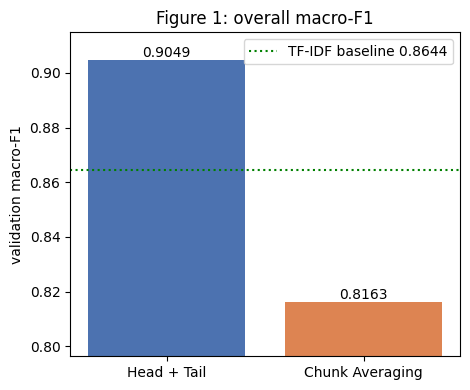

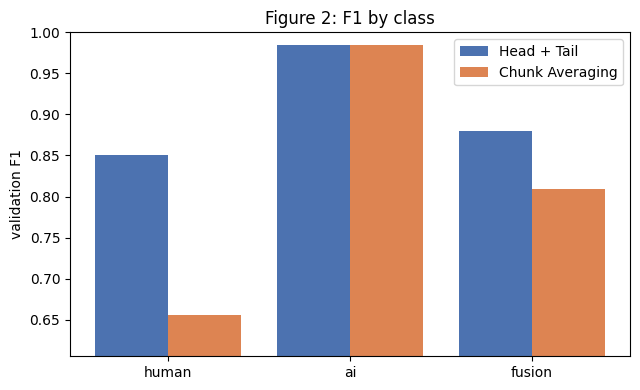

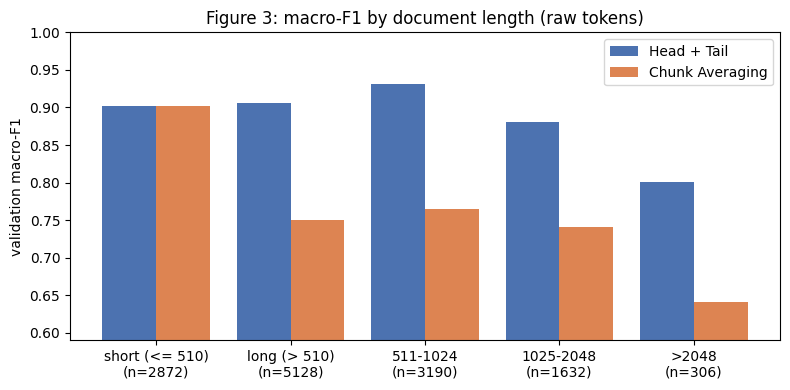

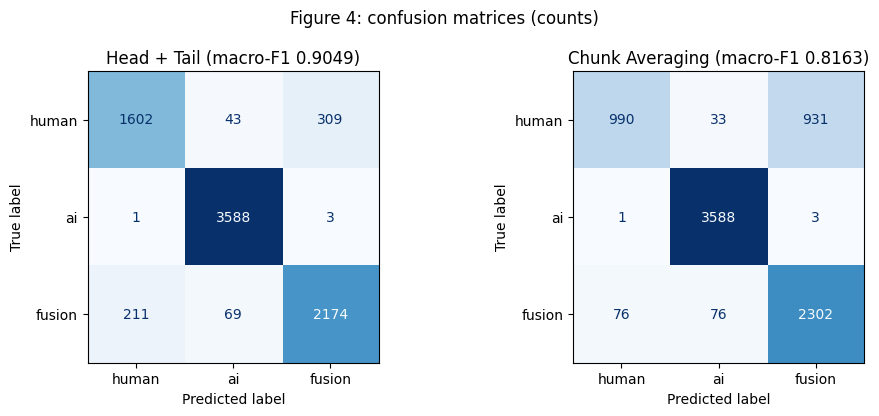

In [11]:
HT_C, CH_C = "#4C72B0", "#DD8452"
fig, ax = plt.subplots(figsize=(4.8, 4)); bars = ax.bar(["Head + Tail", "Chunk Averaging"], [REF["macro_f1"], CH["macro_f1"]], color=[HT_C, CH_C])
for bar in bars: ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001, f"{bar.get_height():.4f}", ha="center")
ax.axhline(BASELINE_F1, color="green", ls=":", label=f"TF-IDF baseline {BASELINE_F1}"); lo = min(REF["macro_f1"], CH["macro_f1"], BASELINE_F1) - 0.02; ax.set_ylim(lo, max(REF["macro_f1"], CH["macro_f1"]) + 0.01)
ax.set_ylabel("validation macro-F1"); ax.set_title("Figure 1: overall macro-F1"); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_overall_macro_f1.png", dpi=150); plt.show()

x = np.arange(3); fig, ax = plt.subplots(figsize=(6.5, 4)); ax.bar(x - 0.2, [REF[f"f1_{l}"] for l in LABELS], 0.4, label="Head + Tail", color=HT_C); ax.bar(x + 0.2, [CH[f"f1_{l}"] for l in LABELS], 0.4, label="Chunk Averaging", color=CH_C)
ax.set_xticks(x); ax.set_xticklabels(LABELS); ax.set_ylim(min(REF["f1_human"], CH["f1_human"], REF["f1_fusion"], CH["f1_fusion"]) - 0.05, 1.0); ax.set_ylabel("validation F1"); ax.set_title("Figure 2: F1 by class"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_f1_by_class.png", dpi=150); plt.show()

g = by_len[by_len.macroF1_headtail.notna()].reset_index(drop=True); x = np.arange(len(g)); fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, g.macroF1_headtail, 0.4, label="Head + Tail", color=HT_C); ax.bar(x + 0.2, g.macroF1_chunks, 0.4, label="Chunk Averaging", color=CH_C)
ax.set_xticks(x); ax.set_xticklabels([f"{a}\n(n={n})" for a, n in zip(g.group, g.n)]); ax.set_ylim(max(0, min(g.macroF1_headtail.min(), g.macroF1_chunks.min()) - 0.05), 1.0)
ax.set_ylabel("validation macro-F1"); ax.set_title("Figure 3: macro-F1 by document length (raw tokens)"); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_by_length.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, pr, t in [(ax[0], pred_ht, f"Head + Tail (macro-F1 {REF['macro_f1']:.4f})"), (ax[1], pred_ch, f"Chunk Averaging (macro-F1 {CH['macro_f1']:.4f})")]:
    ConfusionMatrixDisplay(confusion_matrix(yva, pr, labels=[0, 1, 2]), display_labels=LABELS).plot(cmap="Blues", ax=a, colorbar=False); a.set_title(t)
plt.suptitle("Figure 4: confusion matrices (counts)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_confusion_matrices.png", dpi=150); plt.show()

## 12. Test predictions and submission
Chunk averaging with the same checkpoint and settings. The file is **not** submitted automatically.

In [12]:
P_te, n_ch_te, T_CH_TEST = predict_docs(te_raw, view_chunks, "chunks test"); pred_te = P_te.argmax(1)
print(f"test inference {T_CH_TEST:.0f}s | mean chunks per test document {n_ch_te.mean():.2f}")
submission = pd.DataFrame({"id": test.id.values, "label": [id2label[i] for i in pred_te]}).set_index("id").loc[sub_tmpl.id].reset_index()
assert list(submission.columns) == ["id", "label"] and len(submission) == 25000 and submission.id.is_unique and submission.id.tolist() == sub_tmpl.id.tolist()
assert submission.label.notna().all() and submission.label.isin(LABELS).all()
submission.to_csv(f"{OUT_DIR}/sub_experiment_1_chunk_averaging.csv", index=False); print("saved; predicted label shares:", submission.label.value_counts(normalize=True).round(3).to_dict())

  chunks test: 512/25000 docs (7s)
  chunks test: 2560/25000 docs (34s)
  chunks test: 4608/25000 docs (63s)
  chunks test: 6656/25000 docs (90s)
  chunks test: 8704/25000 docs (117s)
  chunks test: 10752/25000 docs (145s)
  chunks test: 12800/25000 docs (173s)
  chunks test: 14848/25000 docs (200s)
  chunks test: 16896/25000 docs (228s)
  chunks test: 18944/25000 docs (254s)
  chunks test: 20992/25000 docs (282s)
  chunks test: 23040/25000 docs (310s)
  chunks test: 25000/25000 docs (336s)
test inference 336s | mean chunks per test document 2.17
saved; predicted label shares: {'ai': 0.529, 'fusion': 0.318, 'human': 0.154}


## 13. Save experimental artifacts
Probabilities are stored with ids and the class order `human, ai, fusion` (same as the baseline and the encoder) so that they can be aligned by id in later ensembles.

In [13]:
np.savez(f"{OUT_DIR}/experiment_1_chunk_probs.npz", va_ids=va_df.id.values.astype(str), test_ids=test.id.values.astype(str), yva=yva, P_va=P_ch.astype(np.float32), P_te=P_te.astype(np.float32),
         classes=np.array(LABELS), P_va_headtail=P_ht.astype(np.float32))
chk = np.load(f"{OUT_DIR}/experiment_1_chunk_probs.npz", allow_pickle=True); assert chk["P_va"].shape == (8000, 3) and chk["P_te"].shape == (25000, 3) and list(chk["classes"]) == LABELS
va_df[["id", "domain", "lang", "y_true", "pred_headtail", "pred_chunks", "outcome", "n_tokens", "n_chunks"]].assign(**{f"p_chunks_{l}": P_ch[:, i] for i, l in enumerate(LABELS)}, **{f"p_headtail_{l}": P_ht[:, i] for i, l in enumerate(LABELS)}).to_csv(f"{OUT_DIR}/experiment_1_val_predictions.csv", index=False)
json.dump(dict(experiment="long-text chunk averaging vs head+tail, fixed epoch-4 checkpoint, no training", checkpoint_dir=MODEL_DIR, encoder_run_config=RUN_CONFIG, reference_source=REF_SOURCE, label_order=LABELS, label2id=label2id,
               validation_fingerprint=FINGERPRINT, seed=SEED, n_sub=N_SUB, val_frac=VAL_FRAC, chunking=dict(window=WINDOW, stride=STRIDE, max_chunks=MAX_CHUNKS, head_tokens=HEAD_TOKENS, tail_tokens=TAIL_TOKENS, max_len=MAX_LEN),
               reference_results=dict(headtail_macro_f1=REF["macro_f1"], headtail_metrics=REF, chunk_metrics=CH, tfidf_baseline=BASELINE_F1, expected_reference=REF_F1),
               timing_seconds=dict(headtail_val_recomputed=T_HT_VAL, chunks_val=T_CH_VAL, chunks_test=T_CH_TEST), final_inference_batch_size=INFER_BS, torch=torch.__version__, transformers=transformers.__version__),
          open(f"{OUT_DIR}/experiment_1_config.json", "w"), indent=1, default=str)
print(sorted(os.listdir(OUT_DIR)))

['experiment_1_chunk_probs.npz', 'experiment_1_comparison.csv', 'experiment_1_config.json', 'experiment_1_metrics_by_length.csv', 'experiment_1_val_predictions.csv', 'fig1_overall_macro_f1.png', 'fig2_f1_by_class.png', 'fig3_by_length.png', 'fig4_confusion_matrices.png', 'sub_experiment_1_chunk_averaging.csv']


## 14. Conclusions
The lines below are generated from the measured results (no value is typed in). Write your own interpretation for the report underneath.

In [14]:
dm, dfr = CH["macro_f1"] - REF["macro_f1"], CH["recall_fusion"] - REF["recall_fusion"]; L = by_len.set_index("group")
print(f"Overall: head+tail {REF['macro_f1']:.4f}, chunk averaging {CH['macro_f1']:.4f} (difference {dm:+.4f}); paired test p = {p_val:.4f} (chunking fixes {b}, breaks {c}).")
verdict = "supported by the point estimate and statistically distinguishable" if (dm > 0 and p_val < 0.05) else ("higher by the point estimate but NOT statistically distinguishable from head+tail" if dm > 0 else "NOT supported")
print(f"Hypothesis 'chunk averaging improves macro-F1': {verdict}.")
print(f"Fusion recall: {REF['recall_fusion']:.4f} -> {CH['recall_fusion']:.4f} ({dfr:+.4f}); fusion F1: {REF['f1_fusion']:.4f} -> {CH['f1_fusion']:.4f} ({CH['f1_fusion'] - REF['f1_fusion']:+.4f}).")
print(f"Short texts (n={int(L.loc['short (<= 510)', 'n'])}): macro-F1 difference {L.loc['short (<= 510)', 'macroF1_diff']:+.4f} (should be ~0: identical inputs). Long texts (n={int(L.loc['long (> 510)', 'n'])}): {L.loc['long (> 510)', 'macroF1_diff']:+.4f}, fusion recall {L.loc['long (> 510)', 'fusion_recall_diff']:+.4f}.")
print(f"Cost: validation inference {T_CH_VAL:.0f}s vs {T_HT_VAL:.0f}s ({T_CH_VAL / T_HT_VAL:.1f}x), mean {n_ch.mean():.2f} chunks per document. Weigh this against the gain above.")
print("Caveats: one checkpoint and one run; the encoder was fine-tuned on head+tail inputs (a train/inference mismatch for chunks); validation was also used to select epoch 4 and may contain siblings of training texts.")

Overall: head+tail 0.9049, chunk averaging 0.8163 (difference -0.0885); paired test p = 0.0000 (chunking fixes 179, breaks 663).
Hypothesis 'chunk averaging improves macro-F1': NOT supported.
Fusion recall: 0.8859 -> 0.9381 (+0.0522); fusion F1: 0.8802 -> 0.8091 (-0.0710).
Short texts (n=2872): macro-F1 difference +0.0000 (should be ~0: identical inputs). Long texts (n=5128): -0.1555, fusion recall +0.0877.
Cost: validation inference 111s vs 47s (2.4x), mean 2.21 chunks per document. Weigh this against the gain above.
Caveats: one checkpoint and one run; the encoder was fine-tuned on head+tail inputs (a train/inference mismatch for chunks); validation was also used to select epoch 4 and may contain siblings of training texts.


### Experiment 1 — Conclusions

We compared head + tail truncation with sliding-window chunk averaging using the same XLM-RoBERTa checkpoint from epoch 4.

Chunk averaging increased token coverage from 72.8% to 99.5%, but reduced validation macro-F1 from **0.9049 to 0.8163** (−0.0885). The method corrected 179 previously incorrect predictions but introduced 663 new errors.

Interestingly, **fusion recall improved from 0.8859 to 0.9381**, indicating that processing additional document segments helps detect more hybrid human–AI texts. However, fusion F1 decreased from 0.8802 to 0.8091, showing that the improved recall came at the expense of classification precision.

The performance degradation was concentrated in long documents, where macro-F1 decreased by 0.1555. Short-document predictions remained unchanged, as both strategies processed identical inputs.

Chunk averaging was also approximately 2.4 times slower during validation inference (111 vs. 47 seconds).

Overall, the experiment did not support the hypothesis that greater text coverage through simple probability averaging improves macro-F1. The results suggest that additional context can increase fusion sensitivity, but naive aggregation introduces too many false positives.

The original head + tail strategy remains the preferred approach for the final model. Future experiments could investigate class-specific thresholds or more selective chunk aggregation to retain the higher fusion recall without sacrificing overall performance.